# Facilities Operations Analytics

**Business question:** A 120-store grocery chain spends ~$90M over two years on facilities repair work across 25 outside vendors. Where is that money and time going, which vendors and stores are driving problems, and what should operations leadership act on first?

**Data:** ~68,000 work orders (Oct 2024 – Sep 2026) across 6 Texas regions and 8 trades (HVAC, refrigeration, plumbing, etc.).
All data is **synthetic**, produced by `src/generate_data.py` to mirror the patterns of real facilities operations — summer HVAC spikes, older stores breaking more often, vendors that differ in speed, price, and fix quality, and the messy data-quality problems you hit in a real system.

**Approach:** raw CSVs → SQLite → a cleaned staging view (`sql/00_stg_work_orders.sql`) → one SQL file per business question (`sql/01`–`06`) → charts and recommendations here.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from db import build_database, run_sql

pd.set_option("display.float_format", "{:,.1f}".format)

# chart style: thin marks, recessive grid, no chart junk
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8d8c87", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "font.size": 10,
})
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#b8b7b1"
AS_OF = "2026-09-30 23:59"

## 1. Load and profile the data

In [2]:
con = build_database()
for t in ["stores", "vendors", "work_orders"]:
    n = pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", con).n[0]
    print(f"{t:<12} {n:>8,} rows")

stores            120 rows
vendors            25 rows
work_orders    68,354 rows


In [3]:
# Data-quality checks on the RAW table before trusting any numbers
checks = pd.read_sql('''
    SELECT
        SUM(problem_code IS NULL)                         AS missing_problem_code,
        SUM(trade = UPPER(trade) AND trade <> 'HVAC')     AS all_caps_trade_values,
        COUNT(DISTINCT trade)                             AS distinct_trade_values,
        SUM(status = 'Cancelled')                         AS cancelled,
        SUM(status = 'Completed' AND invoice_amount IS NULL) AS completed_without_invoice,
        COUNT(*) - COUNT(DISTINCT work_order_id)          AS duplicate_ids
    FROM work_orders
''', con)
checks.T.rename(columns={0: "count"})

,count
missing_problem_code,326
all_caps_trade_values,106
distinct_trade_values,15
cancelled,1885
completed_without_invoice,0
duplicate_ids,0


**What profiling found and how it's handled** (all in the staging view, so every query uses the same rules):
- **Inconsistent trade labels** — 16 distinct values for 8 real trades (`HVAC` vs `REFRIGERATION` vs `Refrigeration`). Trade is taken from the vendor master instead of the free-text field.
- **Missing problem codes** — filled as `Unknown` rather than dropped, so volume counts stay complete.
- **Cancelled work orders** — kept for volume, excluded from SLA, cost, and repeat-call metrics.
- No duplicate IDs and every completed order has an invoice, so no further fixes needed.

In [4]:
kpis = run_sql(con, "01_kpi_summary.sql")
kpis.T.rename(columns={0: "value"})

,value
total_work_orders,"68,354.0"
completed,"65,843.0"
sla_compliance_pct,68.7
total_spend,"90,618,834.0"
avg_cost_per_wo,"1,376.0"
pct_invoices_over_nte,19.3
open_backlog,626.0


## 2. When does work come in? (seasonality)

Summer vs winter volume lift by trade (%):
trade
HVAC                  82.0
Refrigeration         55.0
Roofing               25.0
Electrical             8.0
Plumbing              -5.0
Doors & Entrances     -7.0
Fire & Life Safety    -7.0
General Maintenance   -9.0


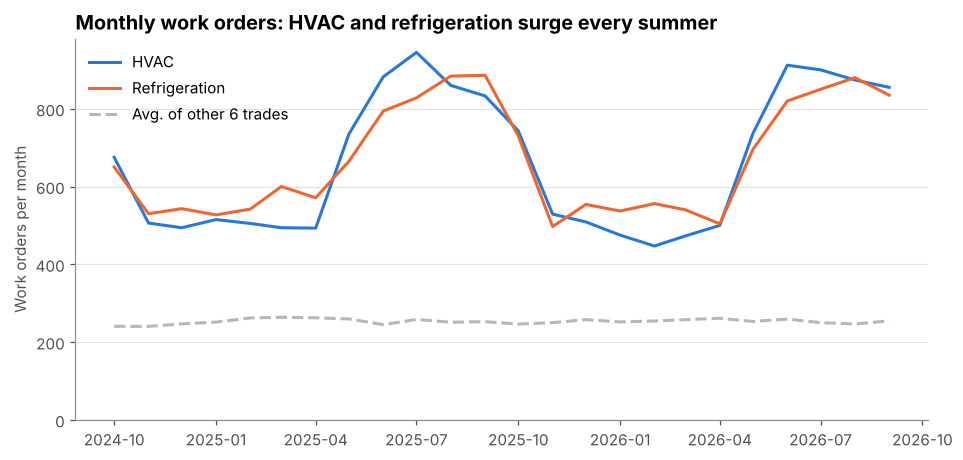

In [5]:
trend = run_sql(con, "02_monthly_trend.sql")
pivot = trend.pivot(index="created_month", columns="trade", values="work_orders")
pivot.index = pd.to_datetime(pivot.index)

focus = ["HVAC", "Refrigeration"]
other = pivot.drop(columns=focus).sum(axis=1)

fig, ax = plt.subplots()
ax.plot(pivot.index, pivot["HVAC"], color=PALETTE[0], lw=2, label="HVAC")
ax.plot(pivot.index, pivot["Refrigeration"], color=PALETTE[1], lw=2, label="Refrigeration")
ax.plot(pivot.index, other / 6, color=GRAY, lw=2, ls="--", label="Avg. of other 6 trades")
ax.set_title("Monthly work orders: HVAC and refrigeration surge every summer")
ax.set_ylabel("Work orders per month")
ax.set_ylim(0)
ax.legend(frameon=False, loc="upper left")
fig.savefig("../images/01_seasonality.png", dpi=150, bbox_inches="tight")

summer = pivot[pivot.index.month.isin([6, 7, 8])]
winter = pivot[pivot.index.month.isin([12, 1, 2])]
lift = (summer.mean() / winter.mean() - 1).sort_values(ascending=False) * 100
print("Summer vs winter volume lift by trade (%):")
print(lift.round(0).to_string())

**Takeaway:** HVAC volume runs about **82% higher in summer than winter** and refrigeration about **55% higher**, while the other six trades are flat. These two trades are also **~67% of total spend**. Summer staffing, vendor capacity agreements, and preventive maintenance should be scheduled for April–May, before the surge, not during it.

## 3. Are we meeting SLAs?
Each priority has a resolution target: P1 Emergency 4h · P2 Urgent 24h · P3 Routine 5 days · P4 Planned 14 days.

In [6]:
sla = run_sql(con, "03_sla_by_priority_region.sql")
sla_pivot = sla.pivot(index="region", columns="priority", values="sla_compliance_pct")
sla_pivot["All priorities"] = (
    sla.assign(met=sla.completed_wos * sla.sla_compliance_pct)
       .groupby("region").met.sum() / sla.groupby("region").completed_wos.sum()
)
sla_pivot.sort_values("All priorities")

priority,P1 - Emergency,P2 - Urgent,P3 - Routine,P4 - Planned,All priorities
region,,,,,
Central TX,58.9,59.3,70.1,72.2,66.7
DFW,63.6,61.4,70.9,73.9,68.3
Houston,58.7,60.5,72.6,74.9,68.6
Rio Grande Valley,64.9,60.6,72.4,74.7,69.1
West TX,61.4,59.3,74.0,76.4,69.6
San Antonio,62.5,62.2,75.0,75.6,70.7


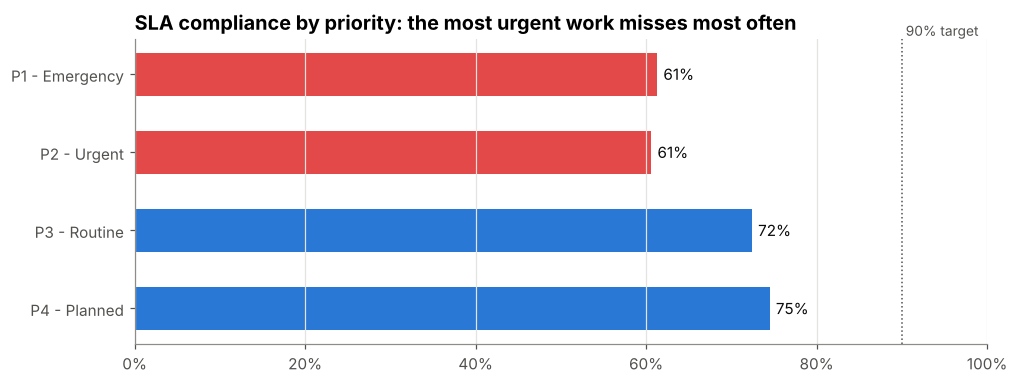

In [7]:
by_pri = (sla.assign(met=sla.completed_wos * sla.sla_compliance_pct / 100)
             .groupby("priority")[["met", "completed_wos"]].sum())
by_pri["pct"] = by_pri.met / by_pri.completed_wos * 100

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = [PALETTE[7] if p < 65 else PALETTE[0] for p in by_pri.pct]
bars = ax.barh(by_pri.index[::-1], by_pri.pct[::-1], color=colors[::-1], height=0.55)
ax.bar_label(bars, fmt="%.0f%%", padding=4, color="#0b0b0b")
ax.axvline(90, color="#52514e", lw=1, ls=":")
ax.text(90, 3.45, " 90% target", color="#52514e", fontsize=9, va="bottom")
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("SLA compliance by priority: the most urgent work misses most often")
fig.savefig("../images/02_sla_by_priority.png", dpi=150, bbox_inches="tight")

**Takeaway:** Overall SLA compliance is **68.7%**, and it's worst exactly where it matters most: **P1 Emergency and P2 Urgent are both ~61%**, well short of a 90% target. Region barely matters (every region lands between 65% and 69%), which points away from a regional staffing problem and toward **who is doing the work** — see the vendor scorecard.

## 4. Vendor scorecard
Speed alone hides the full picture. The scorecard (`sql/04_vendor_scorecard.sql`) puts SLA, average invoice, invoices over the approved not-to-exceed (NTE) amount, and **recall rate** (the share of jobs where the vendor had to come back because the fix didn't hold) side by side, then ranks each vendor within its trade using `RANK() OVER (PARTITION BY trade ...)`.

In [8]:
scorecard = run_sql(con, "04_vendor_scorecard.sql")
scorecard.drop(columns="vendor_id")

,vendor_name,trade,completed_wos,sla_compliance_pct,avg_resolution_hours,avg_invoice,pct_over_nte,recall_pct,sla_rank_in_trade,quality_rank_in_trade
0,Trinity Door Co.,Doors & Entrances,2029,80.1,98.9,563.0,16.5,0.0,2,1
1,Mesquite Door Co.,Doors & Entrances,1760,57.4,154.4,463.0,9.1,0.0,3,1
2,Alamo Door Co.,Doors & Entrances,2214,81.2,100.1,562.0,17.5,11.9,1,3
3,Lone Star Electric,Electrical,1724,92.1,70.2,709.0,13.9,0.0,1,1
4,Mesquite Electric,Electrical,2778,69.8,128.0,771.0,16.6,0.0,3,1
5,Hill Country Electric,Electrical,2258,78.8,114.7,711.0,12.8,3.4,2,3
6,Trinity Fire Protection,Fire & Life Safety,1631,75.0,105.1,"1,122.0",20.0,0.0,1,1
7,Frontier Fire Protection,Fire & Life Safety,1586,66.5,150.6,"1,140.0",22.8,11.6,2,2
8,Cypress Facility Services,General Maintenance,1245,93.9,57.5,286.0,5.9,2.7,2,1
9,Red River Facility Services,General Maintenance,1456,71.3,128.0,438.0,31.4,9.3,4,2


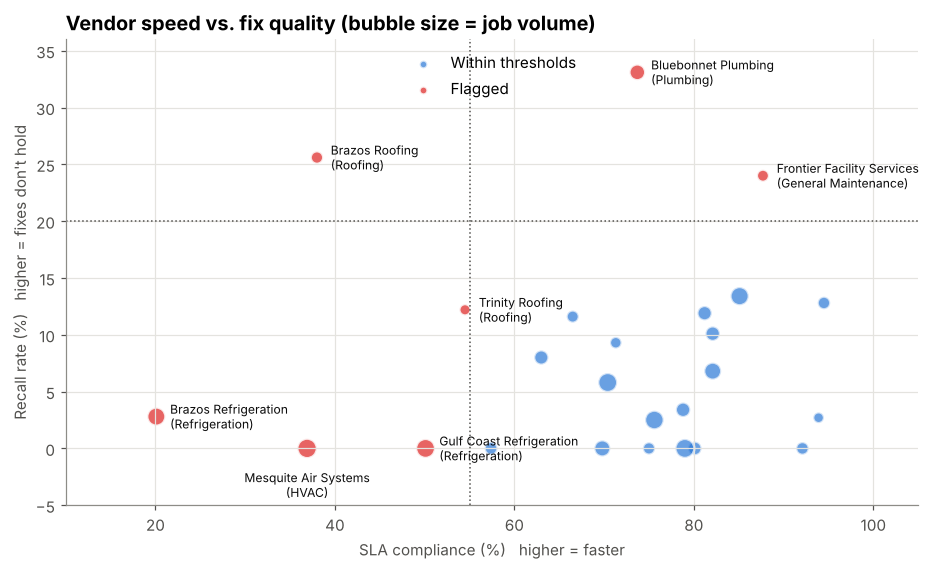

,vendor_name,trade,completed_wos,sla_compliance_pct,recall_pct,avg_invoice,pct_over_nte
11,Frontier Facility Services,General Maintenance,1565,87.7,24.0,356.0,16.9
13,Mesquite Air Systems,HVAC,4070,36.9,0.0,"1,940.0",27.2
18,Bluebonnet Plumbing,Plumbing,2660,73.7,33.1,764.0,29.7
19,Gulf Coast Refrigeration,Refrigeration,3855,50.1,0.0,"2,177.0",18.4
21,Brazos Refrigeration,Refrigeration,3516,20.1,2.8,"1,757.0",8.1
23,Trinity Roofing,Roofing,1370,54.5,12.2,"2,886.0",24.2
24,Brazos Roofing,Roofing,1674,38.0,25.6,"2,541.0",16.2


In [9]:
# Speed vs. fix quality for every vendor
fig, ax = plt.subplots(figsize=(10, 5.5))
flag = (scorecard.sla_compliance_pct < 55) | (scorecard.recall_pct > 20)
ax.scatter(scorecard.sla_compliance_pct[~flag], scorecard.recall_pct[~flag],
           s=scorecard.completed_wos[~flag] / 25, color=PALETTE[0], alpha=0.7,
           edgecolor="white", linewidth=1.5, label="Within thresholds")
ax.scatter(scorecard.sla_compliance_pct[flag], scorecard.recall_pct[flag],
           s=scorecard.completed_wos[flag] / 25, color=PALETTE[7], alpha=0.85,
           edgecolor="white", linewidth=1.5, label="Flagged")
for _, r in scorecard[flag].iterrows():
    below = r.recall_pct < 1 and r.sla_compliance_pct < 45   # avoid overlapping neighbor labels
    ax.annotate(f"{r.vendor_name}\n({r.trade})", (r.sla_compliance_pct, r.recall_pct),
                xytext=(0, -24) if below else (9, 0), textcoords="offset points", fontsize=8,
                va="center", ha="center" if below else "left", color="#0b0b0b")
ax.axvline(55, color="#52514e", lw=1, ls=":")
ax.axhline(20, color="#52514e", lw=1, ls=":")
ax.set_xlim(10, 105)
ax.set_xlabel("SLA compliance (%)   higher = faster")
ax.set_ylabel("Recall rate (%)   higher = fixes don't hold")
ax.grid(axis="x")
ax.legend(frameon=False, loc="upper center", markerscale=0.5)
ax.set_ylim(-5, 36)
ax.set_title("Vendor speed vs. fix quality (bubble size = job volume)")
fig.savefig("../images/03_vendor_scorecard.png", dpi=150, bbox_inches="tight")
scorecard[flag][["vendor_name", "trade", "completed_wos", "sla_compliance_pct",
                 "recall_pct", "avg_invoice", "pct_over_nte"]]

In [10]:
# What do recalls cost? Every recall is a second paid visit.
recall_spend = pd.read_sql(
    "SELECT vendor_name, trade, COUNT(*) AS recalls, SUM(invoice_amount) AS recall_spend "
    "FROM stg_work_orders "
    "WHERE recall_of_work_order_id IS NOT NULL AND status = 'Completed' "
    "GROUP BY vendor_name, trade ORDER BY recall_spend DESC", con)
total_recall = recall_spend.recall_spend.sum()
print(f"Total spend on recall visits: ${total_recall:,.0f} "
      f"({total_recall / kpis.total_spend[0]:.1%} of all spend)")
recall_spend.head(5)

Total spend on recall visits: $5,144,055 (5.7% of all spend)


,vendor_name,trade,recalls,recall_spend
0,Brazos Roofing,Roofing,428,"1,057,732.7"
1,Alamo Air Systems,HVAC,477,"725,198.0"
2,Bluebonnet Plumbing,Plumbing,878,"706,012.8"
3,Trinity Roofing,Roofing,165,"461,011.5"
4,Bluebonnet Refrigeration,Refrigeration,222,"453,224.7"


**Takeaway:** Seven of 25 vendors are flagged, and they handle **31% of completed jobs but cause 50% of all SLA misses**. They fail in two different ways, which need two different fixes:
- **Slow but solid** (bottom-left): *Brazos Refrigeration* is the cheapest refrigeration vendor (~$1,760/job vs. ~$2,100+ for peers) but meets SLA only **20%** of the time. Cheapest isn't best when a warm case means lost product.
- **Fast but sloppy** (top-right): *Bluebonnet Plumbing* and *Frontier Facility Services* close jobs on time, but a quarter to a third of their fixes need a callback. *Brazos Roofing* is both slow **and** has a 26% recall rate.

Recall visits alone cost **~$5.1M (5.7% of spend)** over two years.

## 5. What's stuck in the open backlog?

Open work orders: 626  |  older than 30 days: 122 (19%)


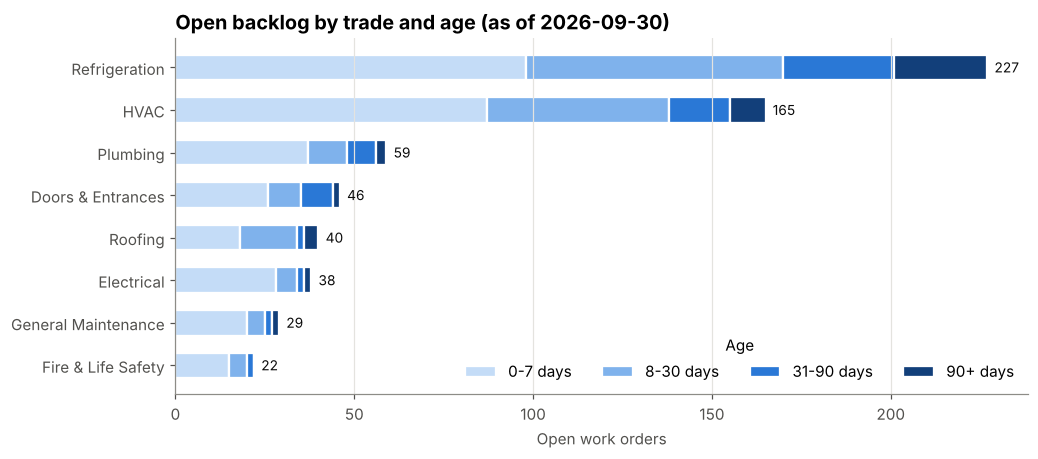

In [11]:
aging = run_sql(con, "05_backlog_aging.sql", as_of=AS_OF)
age_pivot = aging.pivot(index="trade", columns="age_bucket", values="open_wos").fillna(0)
age_pivot = age_pivot.loc[age_pivot.sum(axis=1).sort_values().index]
age_pivot.columns = [c.split(") ")[1] for c in age_pivot.columns]

seq = ["#c4dcf7", "#7fb2ec", "#2a78d6", "#123f7a"]  # one hue, light -> dark = older
fig, ax = plt.subplots(figsize=(10, 4.2))
left = pd.Series(0, index=age_pivot.index)
for col, color in zip(age_pivot.columns, seq):
    ax.barh(age_pivot.index, age_pivot[col], left=left, color=color, height=0.6,
            label=col, edgecolor="white", linewidth=1.5)
    left += age_pivot[col]
for y, total in enumerate(left):
    ax.text(total + 2, y, f"{int(total)}", va="center", fontsize=9, color="#0b0b0b")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(title="Age", frameon=False, ncol=4, loc="lower right")
ax.set_title(f"Open backlog by trade and age (as of {AS_OF[:10]})")
ax.set_xlabel("Open work orders")
fig.savefig("../images/04_backlog_aging.png", dpi=150, bbox_inches="tight")

stale = aging[aging.age_bucket.str.contains("31-90|90\\+")].open_wos.sum()
print(f"Open work orders: {int(aging.open_wos.sum())}  |  older than 30 days: {int(stale)} "
      f"({stale / aging.open_wos.sum():.0%})")

**Takeaway:** Most of the 626 open orders are fresh, but **122 (19%) are more than 30 days old**, concentrated in refrigeration and HVAC. Work that sits that long is usually waiting on parts, quotes, or approvals, not labor, so a weekly review of 30+ day items with vendors would clear most of it.

## 6. Which stores are the hotspots?
Normalizing by square footage so big stores don't dominate just for being big.

In [12]:
stores = run_sql(con, "06_store_hotspots.sql")
stores["store_age"] = 2026 - stores.open_year
stores["age_band"] = pd.cut(stores.store_age, [0, 10, 20, 30, 50],
                            labels=["0-10 yrs", "11-20 yrs", "21-30 yrs", "31+ yrs"])
band = stores.groupby("age_band", observed=True).agg(
    stores=("store_id", "count"),
    avg_wos_per_10k_sqft=("wos_per_10k_sqft", "mean"),
    avg_spend_per_store=("total_spend", "mean"))
band

,stores,avg_wos_per_10k_sqft,avg_spend_per_store
age_band,,,
0-10 yrs,22,63.6,"667,624.9"
11-20 yrs,30,69.3,"616,326.9"
21-30 yrs,27,71.0,"828,107.5"
31+ yrs,41,79.8,"855,667.9"


Correlation (store age vs. WOs per 10k sq ft): 0.43


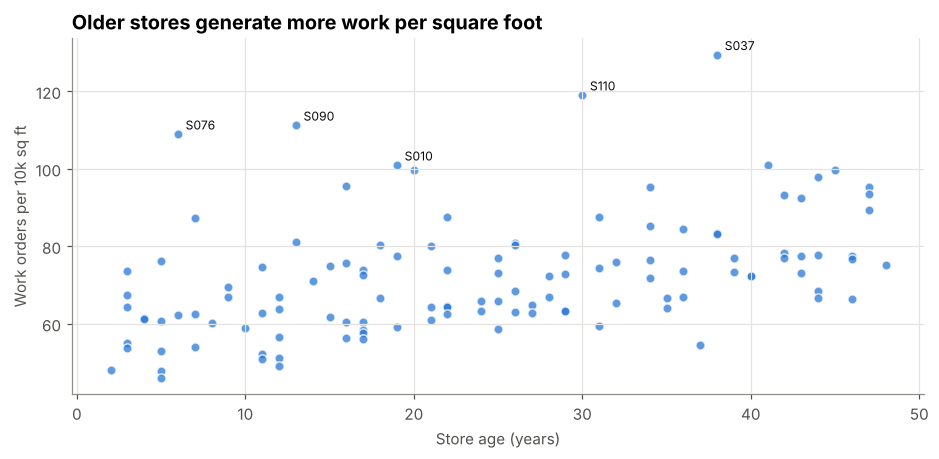

,store_id,region,store_format,store_age,work_orders,wos_per_10k_sqft,total_spend
0,S037,Houston,Express,38,272,129.5,"364,110.0"
1,S110,West TX,Express,30,268,119.1,"343,485.0"
2,S090,DFW,Express,13,256,111.3,"310,064.0"
3,S076,DFW,Express,6,218,109.0,"287,991.0"
4,S010,Central TX,Express,19,298,101.0,"352,420.0"
5,S042,Houston,Express,41,313,101.0,"383,880.0"
6,S070,San Antonio,Standard,45,568,99.6,"802,059.0"
7,S117,West TX,Express,20,254,99.6,"344,878.0"
8,S043,Houston,Large,44,921,98.0,"1,138,592.0"
9,S002,Central TX,Express,16,220,95.7,"298,429.0"


In [13]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.scatter(stores.store_age, stores.wos_per_10k_sqft, s=36, color=PALETTE[0],
           alpha=0.75, edgecolor="white", linewidth=1)
top = stores.nlargest(5, "wos_per_10k_sqft")
for _, r in top.iterrows():
    ax.annotate(r.store_id, (r.store_age, r.wos_per_10k_sqft), xytext=(5, 3),
                textcoords="offset points", fontsize=8, color="#0b0b0b")
ax.set_xlabel("Store age (years)")
ax.set_ylabel("Work orders per 10k sq ft")
ax.grid(axis="x")
ax.set_title("Older stores generate more work per square foot")
fig.savefig("../images/05_store_age.png", dpi=150, bbox_inches="tight")
print("Correlation (store age vs. WOs per 10k sq ft):",
      round(stores.store_age.corr(stores.wos_per_10k_sqft), 2))
stores.head(10)[["store_id", "region", "store_format", "store_age", "work_orders", "wos_per_10k_sqft", "total_spend"]]

**Takeaway:** Store age is a real driver: stores **31+ years old generate ~25% more work per square foot** than stores under 10 years old, and spend ~$190K more per store over two years. Note the per-sq-ft ranking is dominated by small Express stores (8 of the top 10), since fixed equipment like HVAC units and coolers doesn't shrink with the building. For capital planning, use both views: per-sq-ft to find inefficiency, total spend to find the biggest dollars.

## 7. Recommendations

| # | Action | Evidence | Estimated impact |
|---|---|---|---|
| 1 | **Put the 7 flagged vendors on performance plans**; shift P1/P2 work to top-ranked vendors in the same trade | Flagged vendors = 31% of jobs, 50% of SLA misses | Largest single lever on emergency SLA |
| 2 | **Require root-cause notes and a 30-day warranty** on repeat-prone trades (plumbing, roofing, general maintenance) | ~$5.1M spent on recall visits | Recover a share of recall spend from vendors |
| 3 | **Enforce NTE approvals** before invoice payment | 19% of invoices exceed NTE, ~$7.4M over approved amounts | Direct cost avoidance |
| 4 | **Pre-season HVAC/refrigeration PM in April–May** and lock vendor capacity before summer | +82% / +55% summer volume, 67% of spend | Smaller summer backlog, fewer emergency calls |
| 5 | **Weekly 30+ day backlog review** with vendors | 122 orders older than 30 days | Faster close-out, cleaner data |
| 6 | **Prioritize the oldest stores in capital planning** (replace vs. repair) | 31+ yr stores: +25% work per sq ft | Lower long-run run-rate |

---
*Next iteration ideas:* move the SQL into a dbt project with tests, build a Tableau/Power BI dashboard on the staging view, and train a model to predict which new work orders will breach SLA so dispatchers can intervene early.